# GEOG 592 — Week 10 Homework
## Atlas

## Data Preparation and Spatial Join

In [43]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

<Axes: >

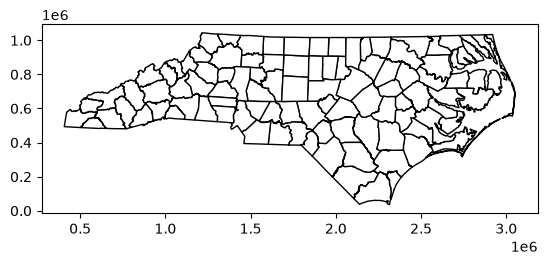

In [44]:
# getting the US census data

url_0 = "https://www2.census.gov/geo/tiger/GENZ2024/shp/" # url for census tiger data 
url_county = "cb_2024_us_county_500k.zip" # county level
url_state = "cb_2024_us_state_500k.zip" # state level 


## code for county level data 

counties = gpd.read_file(url_0+url_county)
nc_counties = counties.loc[counties["STATEFP"] == "37"].to_crs(6543).copy()
nc_counties.plot(edgecolor="black", facecolor="white")

## Spatial Join

In [45]:
# Read data
compost = gpd.read_file("data/Permitted_Compost_Facilities.geojson")

compost

,PermitID,LocationID,PermitName,Address1,City,Zip,County,Latitude,Longitude,PrimaryWasteType,PermitStatus,OrigPermitIssueDate,PermitIssueDate,PermitExpDate,EnvMonitoring,FinancialAssurance,FID,geometry
0,0103-COMPOST-1992,P0423,Alamance County Yard Waste,Alfred Road (S.R. 2164),Graham,27253,Alamance,36.01717,-79.34704,YW,InactiveClosed,NaT,NaT,NaT,N,N,1,POINT (-79.34704 36.01717)
1,0106-COMPOST-,P1034,Carolina Resource Recovery,3285 Jones Road,Mebane,27302,Alamance,36.02025,-79.27415,Type I,InactiveClosed,2000-09-04,NaT,NaT,N,N,2,POINT (-79.27415 36.02025)
2,0109-COMPOST-2025,P1383,Mebane Shrubbery,1750 N. NC Hwy. 49,Burlington,27217,Alamance,36.13000,-79.34700,Type I,Active,2025-08-18,2025-08-18,2035-08-18,N,N,3,POINT (-79.347 36.13)
3,0111-COMPOST-2025,P1375,Key Landfill - Large Type 1,2380 Sandy Cross Road,Burlington,27217,Alamance,36.13984,-79.35791,Type I,Active,2025-05-30,2025-05-30,2035-05-30,N,N,4,POINT (-79.35791 36.13984)
4,0404-COMPOST-,P1018,Brown Creek Correctional Facility,248 Prison Camp Road,Polkton,28135,Anson,34.98872,-80.18125,Type III,InactiveClosed,2005-09-27,NaT,NaT,N,N,5,POINT (-80.18125 34.98872)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
104,9504-COMPOST-2001,P1028,Appalachian State University Compost Facility,265 Dale Street,Boone,28608,Watauga,36.20597,-81.65582,Type III,Active,2011-03-21,2022-05-06,2032-05-06,N,N,105,POINT (-81.65582 36.20597)
105,9505-COMPOST-,P1249,Triple T Pumping Compost Facility,795 Troy Norris Rd,Boone,28607,Watauga,36.28566,-81.64509,Type III,InactivePermitted,2012-07-30,2012-07-30,2017-07-30,N,N,106,POINT (-81.64509 36.28566)
106,9705-COMPOST-2023,P1391,Wilkes Abattoir Compost,257 Brewer Road,Hays,28635,Wilkes,36.24810,-81.12495,Type III,Active,NaT,NaT,NaT,N,Y,107,POINT (-81.12495 36.2481)
107,9810-COMPOST-2016,P1275,D & D Organic Farming Compost Facility,7984 Pelt Road,Stantonsburg,27883,Wilson,35.59811,-77.87549,Type III,Active,2016-12-16,2016-12-16,2021-12-16,N,NaN,108,POINT (-77.87549 35.59811)


In [46]:
compost.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [47]:
compost = compost.to_crs(epsg=6543)
compost.crs

<Projected CRS: EPSG:6543>
Name: NAD83(2011) / North Carolina (ftUS)
Axis Info [cartesian]:
- X[east]: Easting (US survey foot)
- Y[north]: Northing (US survey foot)
Area of Use:
- name: United States (USA) - North Carolina - counties of Alamance; Alexander; Alleghany; Anson; Ashe; Avery; Beaufort; Bertie; Bladen; Brunswick; Buncombe; Burke; Cabarrus; Caldwell; Camden; Carteret; Caswell; Catawba; Chatham; Cherokee; Chowan; Clay; Cleveland; Columbus; Craven; Cumberland; Currituck; Dare; Davidson; Davie; Duplin; Durham; Edgecombe; Forsyth; Franklin; Gaston; Gates; Graham; Granville; Greene; Guilford; Halifax; Harnett; Haywood; Henderson; Hertford; Hoke; Hyde; Iredell; Jackson; Johnston; Jones; Lee; Lenoir; Lincoln; Macon; Madison; Martin; McDowell; Mecklenburg; Mitchell; Montgomery; Moore; Nash; New Hanover; Northampton; Onslow; Orange; Pamlico; Pasquotank; Pender; Perquimans; Person; Pitt; Polk; Randolph; Richmond; Robeson; Rockingham; Rowan; Rutherford; Sampson; Scotland; Stanly; Stoke

In [48]:
# Filtering only columns of interest
compost = compost[["PermitName","geometry"]].copy()
compost

,PermitName,geometry
0,Alamance County Yard Waste,POINT (1897368.306 825329.397)
1,Carolina Resource Recovery,POINT (1918927.894 826381.196)
2,Mebane Shrubbery,POINT (1897523.158 866402.03)
3,Key Landfill - Large Type 1,POINT (1894314.109 869994.939)
4,Brown Creek Correctional Facility,POINT (1646214.847 452928.732)
...,...,...
104,Appalachian State University Compost Facility,POINT (1216508.35 904360.761)
105,Triple T Pumping Compost Facility,POINT (1220447.326 933277.609)
106,Wilkes Abattoir Compost,POINT (1373422.979 915923.578)
107,D & D Organic Farming Compost Facility,POINT (2334279.98 674506.506)


In [49]:
# spatial join
compost_by_county = gpd.sjoin(compost, nc_counties, predicate='within')
compost_by_county

,PermitName,geometry,index_right,STATEFP,COUNTYFP,COUNTYNS,GEOIDFQ,GEOID,NAME,NAMELSAD,STUSPS,STATE_NAME,LSAD,ALAND,AWATER
0,Alamance County Yard Waste,POINT (1897368.306 825329.397),1930,37,001,01008531,0500000US37001,37001,Alamance,Alamance County,NC,North Carolina,06,1096763237,27913357
1,Carolina Resource Recovery,POINT (1918927.894 826381.196),1930,37,001,01008531,0500000US37001,37001,Alamance,Alamance County,NC,North Carolina,06,1096763237,27913357
2,Mebane Shrubbery,POINT (1897523.158 866402.03),1930,37,001,01008531,0500000US37001,37001,Alamance,Alamance County,NC,North Carolina,06,1096763237,27913357
3,Key Landfill - Large Type 1,POINT (1894314.109 869994.939),1930,37,001,01008531,0500000US37001,37001,Alamance,Alamance County,NC,North Carolina,06,1096763237,27913357
4,Brown Creek Correctional Facility,POINT (1646214.847 452928.732),344,37,007,01008534,0500000US37007,37007,Anson,Anson County,NC,North Carolina,06,1376478141,14603213
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
104,Appalachian State University Compost Facility,POINT (1216508.35 904360.761),2243,37,189,01008594,0500000US37189,37189,Watauga,Watauga County,NC,North Carolina,06,809214845,2271720
105,Triple T Pumping Compost Facility,POINT (1220447.326 933277.609),2243,37,189,01008594,0500000US37189,37189,Watauga,Watauga County,NC,North Carolina,06,809214845,2271720
106,Wilkes Abattoir Compost,POINT (1373422.979 915923.578),217,37,193,01008595,0500000US37193,37193,Wilkes,Wilkes County,NC,North Carolina,06,1952016296,6854041
107,D & D Organic Farming Compost Facility,POINT (2334279.98 674506.506),2233,37,195,01008596,0500000US37195,37195,Wilson,Wilson County,NC,North Carolina,06,952012884,14332533


In [50]:
# charger count in each county
compost_count = compost_by_county["NAME"].value_counts()

compost_count

NAME
Mecklenburg     10
Buncombe         7
Forsyth          6
Guilford         5
Wake             5
Alamance         4
Cabarrus         4
Sampson          4
Anson            3
Craven           3
Durham           3
Edgecombe        3
Gaston           3
Catawba          2
Chatham          2
Chowan           2
Davidson         2
Davie            2
Franklin         2
Halifax          2
Haywood          2
Macon            2
Montgomery       2
Nash             2
New Hanover      2
Onslow           2
Randolph         2
Scotland         2
Watauga          2
Wilson           2
Brunswick        1
Cleveland        1
Cumberland       1
Hyde             1
Lee              1
Madison          1
Mitchell         1
Pasquotank       1
Pender           1
Rockingham       1
Rowan            1
Transylvania     1
Union            1
Jones            1
Wilkes           1
Name: count, dtype: int64

In [51]:
# creating new table
compost_count_table = compost_count.reset_index()

compost_count_table.columns = ["NAME", "Compost"]

compost_count_table

,NAME,Compost
0,Mecklenburg,10
1,Buncombe,7
2,Forsyth,6
3,Guilford,5
4,Wake,5
5,Alamance,4
6,Cabarrus,4
7,Sampson,4
8,Anson,3
9,Craven,3


In [52]:
# add new column
compost_by_county = nc_counties.merge(compost_count_table, on="NAME", how="left")
compost_by_county["Compost"] = compost_by_county["Compost"].fillna(0)
compost_by_county["Compost"] = compost_by_county["Compost"].astype(int)
compost_by_county

,STATEFP,COUNTYFP,COUNTYNS,GEOIDFQ,GEOID,NAME,NAMELSAD,STUSPS,STATE_NAME,LSAD,ALAND,AWATER,geometry,Compost
0,37,047,01026339,0500000US37047,37047,Columbus,Columbus County,NC,North Carolina,06,2429920494,43711694,"POLYGON ((1978481.879 199930.366, 1979179.073 ...",0
1,37,039,01008545,0500000US37039,37039,Cherokee,Cherokee County,NC,North Carolina,06,1179842036,28813680,"POLYGON ((408779.421 505506.597, 408786.42 505...",0
2,37,149,01008579,0500000US37149,37149,Polk,Polk County,NC,North Carolina,06,615606325,1964035,"POLYGON ((997042.881 555579.496, 997049.933 55...",0
3,37,009,01008535,0500000US37009,37009,Ashe,Ashe County,NC,North Carolina,06,1104023356,8058446,"POLYGON ((1193571.583 980437.246, 1194562.461 ...",0
4,37,055,01026133,0500000US37055,37055,Dare,Dare County,NC,North Carolina,06,992558552,3000513281,"MULTIPOLYGON (((2968803.433 811517.819, 297128...",0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,37,069,01008553,0500000US37069,37069,Franklin,Franklin County,NC,North Carolina,06,1273761678,7173998,"POLYGON ((2134342.078 839845.822, 2134479.82 8...",2
96,37,097,01008565,0500000US37097,37097,Iredell,Iredell County,NC,North Carolina,06,1487784939,59453223,"POLYGON ((1374327.812 744224.956, 1375216.065 ...",0
97,37,187,01026331,0500000US37187,37187,Washington,Washington County,NC,North Carolina,06,897456201,195282199,"POLYGON ((2638938.588 723898.852, 2640001.911 ...",0
98,37,071,01008554,0500000US37071,37071,Gaston,Gaston County,NC,North Carolina,06,921389625,20549066,"POLYGON ((1268485.378 616765.02, 1282096.491 6...",3


In [53]:
# filtering for only needed columns
compost_by_county = compost_by_county[["NAME", "geometry", "Compost"]].copy()
compost_by_county

,NAME,geometry,Compost
0,Columbus,"POLYGON ((1978481.879 199930.366, 1979179.073 ...",0
1,Cherokee,"POLYGON ((408779.421 505506.597, 408786.42 505...",0
2,Polk,"POLYGON ((997042.881 555579.496, 997049.933 55...",0
3,Ashe,"POLYGON ((1193571.583 980437.246, 1194562.461 ...",0
4,Dare,"MULTIPOLYGON (((2968803.433 811517.819, 297128...",0
...,...,...,...
95,Franklin,"POLYGON ((2134342.078 839845.822, 2134479.82 8...",2
96,Iredell,"POLYGON ((1374327.812 744224.956, 1375216.065 ...",0
97,Washington,"POLYGON ((2638938.588 723898.852, 2640001.911 ...",0
98,Gaston,"POLYGON ((1268485.378 616765.02, 1282096.491 6...",3


## Atlas 

In [55]:
# function with county and ax being the parameter

def county_map(county, ax):
    selected = compost_by_county[compost_by_county["NAME"] == county]
    selected.plot(ax=ax, edgecolor="black", facecolor="limegreen")
    ax.set_axis_off()


def locator_map(county, ax):
    selected = compost_by_county[compost_by_county["NAME"] == county]
    compost_by_county.plot(ax=ax, edgecolor="gray", facecolor="white")
    selected.plot(ax=ax, edgecolor="black", facecolor="limegreen")
    ax.set_axis_off()

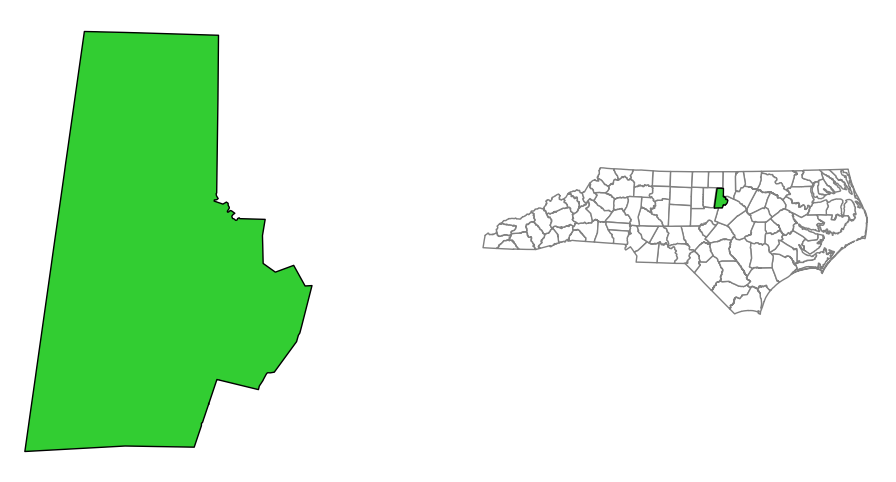

In [56]:
# Putting them in the same figure
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

county_map("Durham", axes[0])
locator_map("Durham", axes[1])

plt.show()

In [57]:
# Let's make this a funtions too and add the fig.save into a pdf
def county_figure(county):
    fig, axes = plt.subplots(
        2, 1,
        figsize=(8, 10),
        gridspec_kw={"height_ratios": [3, 1]}
    )

    county_map(county, axes[0])
    locator_map(county, axes[1])

    fig.suptitle(f"{county} County", fontsize=20)

    fig.savefig(f"{county}_County.pdf")
    plt.close(fig)

In [58]:
county_figure("Durham")

In [59]:
## Put all pdfs into one PDF

def county_figure(county, pdf):
    fig, axes = plt.subplots(
        2, 1,
        figsize=(8, 10),
        gridspec_kw={"height_ratios": [3, 1]}
    )

    county_map(county, axes[0])
    locator_map(county, axes[1])

    fig.suptitle(f"{county} County", fontsize=20)

    pdf.savefig(fig)
    plt.close(fig)

In [60]:
from matplotlib.backends.backend_pdf import PdfPages 

In [ ]:
with PdfPages("NC_Counties.pdf") as pdf:
    for county in compost_by_county["NAME"]:
        county_figure(county, pdf)

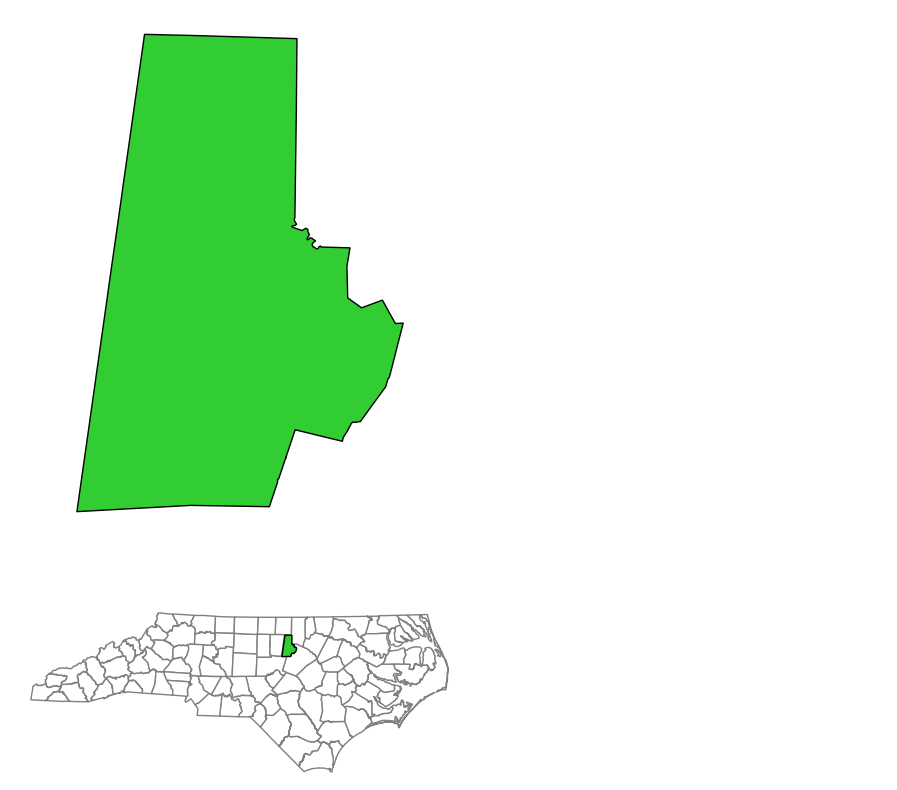

In [83]:
fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 10),
    gridspec_kw={
        "height_ratios": [3, 1],
        "width_ratios": [2, 1]
    }
)

county_map("Durham", axes[0, 0])
locator_map("Durham", axes[1, 0])

for ax in axes.flat:
    ax.set_axis_off()

Text(0.5, 0.98, 'Durham')

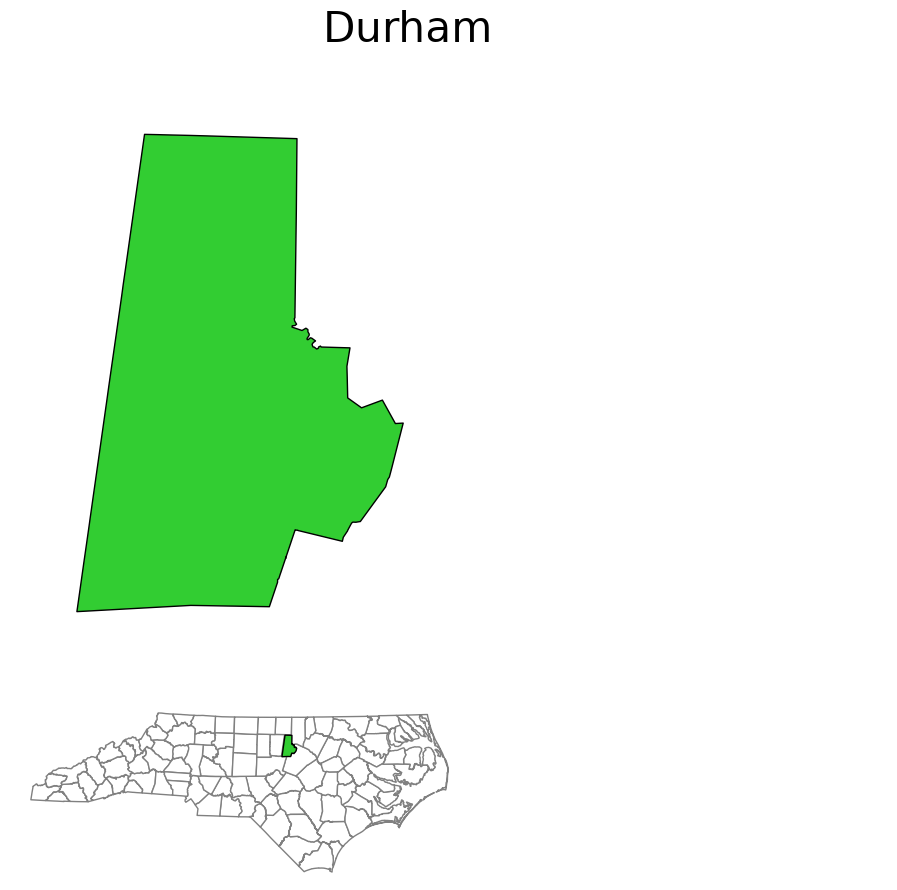

In [68]:
fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 10),
    gridspec_kw={
        "height_ratios": [3, 1],
        "width_ratios": [2, 1]
    }
)

county_map("Durham", axes[0, 0])
locator_map("Durham", axes[1, 0])

for ax in axes.flat:
    ax.set_axis_off()

fig.suptitle("Durham", fontsize=30)


In [95]:
# Defining number of facilities map function
def county_info(county, ax):
    selected = compost_by_county[compost_by_county["NAME"] == county]

    facilities = selected["Compost"].iloc[0]

    ax.text(
        -0.5, 0.8,
        f"Permitted Compost Facilities: {facilities}",
        transform=ax.transAxes,
        fontsize=14,
        color="black",
        va="top"
    )

    ax.set_axis_off()

Text(0.5, 0.98, 'Durham')

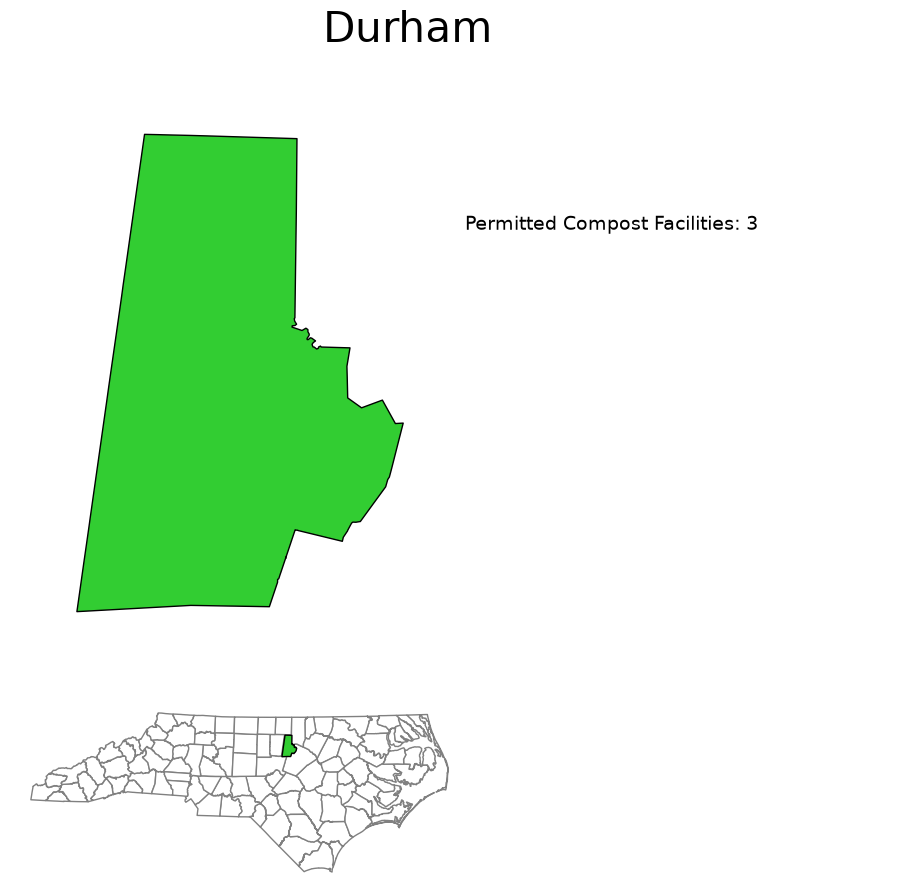

In [96]:
fig, axes = plt.subplots(
    2, 2,
    figsize=(12, 10),
    gridspec_kw={
        "height_ratios": [3, 1],
        "width_ratios": [2, 1]
    }
)

county_map("Durham", axes[0, 0])
locator_map("Durham", axes[1, 0])
county_info("Durham",  axes[0,1])

for ax in axes.flat:
    ax.set_axis_off()

fig.suptitle("Durham", fontsize=30)

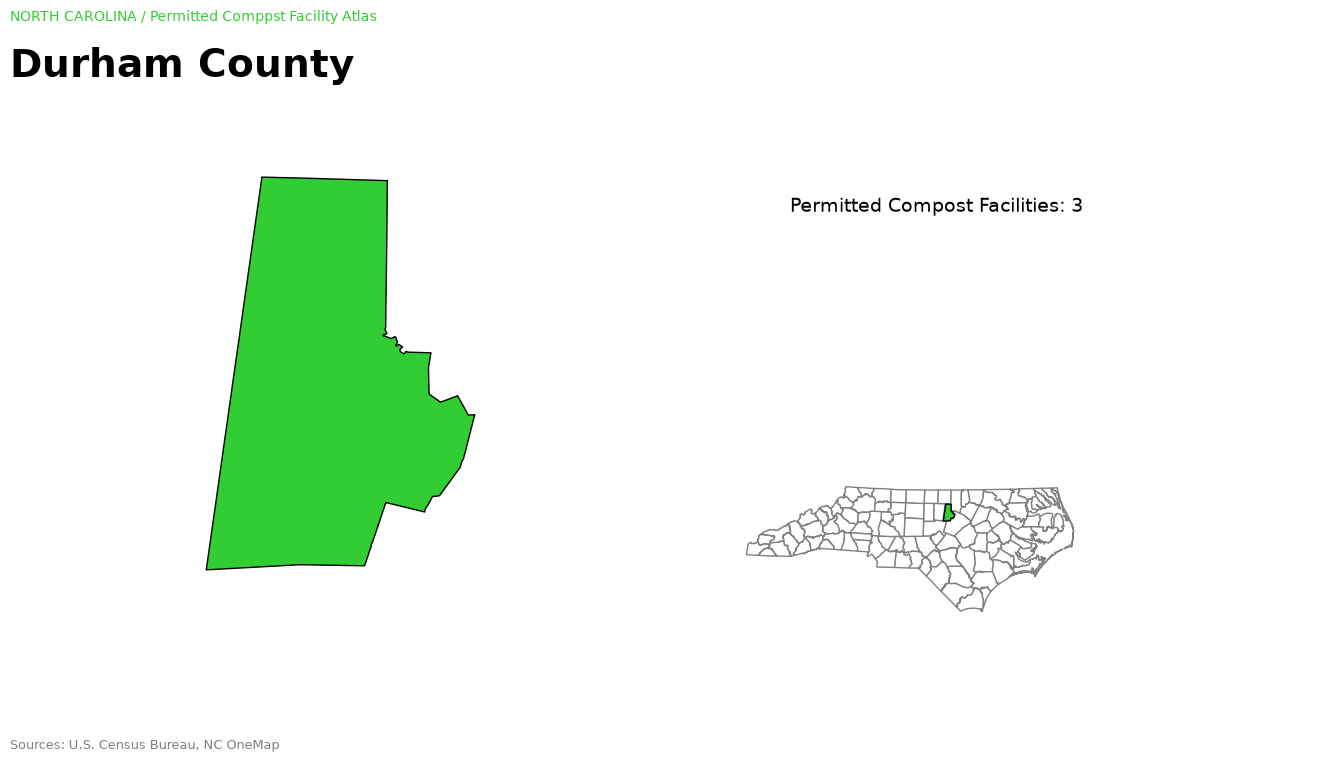

In [106]:
county = "Durham"

fig = plt.figure(figsize=(12, 8))

# [left, bottom, width, height] as fractions of the figure
ax_county = fig.add_axes([0.05, 0.23, 0.55, 0.54])
ax_locator = fig.add_axes([0.65, 0.12, 0.30, 0.32])
ax_info = fig.add_axes([0.85, 0.48, 0.30, 0.30])

county_map(county, ax_county)
locator_map(county, ax_locator)
county_info(county, ax_info)

# Page heading
fig.text(
    0.05, 0.94,
    "NORTH CAROLINA / Permitted Comppst Facility Atlas",
    fontsize=10,
    color="limegreen"
)

fig.text(
    0.05, 0.87,
    f"{county} County",
    fontsize=28,
    fontweight="bold"
)

# Footer
fig.text(
    0.05, 0.03,
    "Sources: U.S. Census Bureau, NC OneMap",
    fontsize=9,
    color="gray"
)

plt.show()

In [109]:
def county_figure(county, pdf):

    fig = plt.figure(figsize=(12, 8))

    # [left, bottom, width, height] as fractions of the figure
    ax_county = fig.add_axes([0.05, 0.23, 0.55, 0.54])
    ax_locator = fig.add_axes([0.65, 0.12, 0.30, 0.32])
    ax_info = fig.add_axes([0.85, 0.48, 0.30, 0.30])


    county_map(county, ax_county)
    locator_map(county, ax_locator)
    county_info(county, ax_info)

    # Page heading
    fig.text(
        0.05, 0.94,
        "NORTH CAROLINA / Permitted Compost Facility Atlas",
        fontsize=10,
        color="olivedrab"
    )

    fig.text(
        0.05, 0.87,
        f"{county} County",
        fontsize=28,
        fontweight="bold"
    )

    # Footer
    fig.text(
        0.05, 0.03,
        "Sources: U.S. Census Bureau, NC OneMap",
        fontsize=9,
        color="gray"
    )

    pdf.savefig(fig, dpi=50)
    plt.close(fig)

In [110]:
with PdfPages("NC_Compost_Counties.pdf") as pdf:  
    for county in compost_by_county["NAME"]:
        county_figure(county, pdf)

In [111]:
# alphabetical order
compost_by_county = compost_by_county.sort_values("NAME").reset_index(drop=True)

with PdfPages("NC_Compost_Counties.pdf") as pdf:  
    for county in compost_by_county["NAME"]:
        county_figure(county, pdf)

## AI Usage
**Section: add new column**\
Verified how to replace NaN values with 0 (Gemini)